In [10]:
import numpy as np
import matplotlib.pyplot as plt

# W01A
##### Write classes that implement drawing samples from the uniform distribution and from the normal distribution.

In [11]:
class Distribution():
    def __init__(self, size=1000000, min=-1, max=1):
        self.min = min
        self.max = max
        self.size = size
        self.set_xs()

    def plot(self, ax):
        bins = 30
        # Use custom edges defined by min and max
        edges = np.linspace(self.min, self.max, bins)
        
        # Plot with nice styling (density=True for probability density, edgecolor for crisp bars)
        ax.hist(self.xs, bins=edges, density=True, alpha=0.7, color="#7A59AB",  edgecolor="white")
        
        # Add titles or labels if desired
        ax.set_xlim(self.min, self.max)
        ax.grid(True, linestyle='--', alpha=0.5)


In [12]:
class Uniform(Distribution):

    def set_xs(self):
        self.min = 0
        self.max = 1
        self.xs = np.random.rand(self.size)

class Normal(Distribution):

    def set_xs(self):
        self.min = -4
        self.max = 4
        self.xs = np.random.randn(self.size)

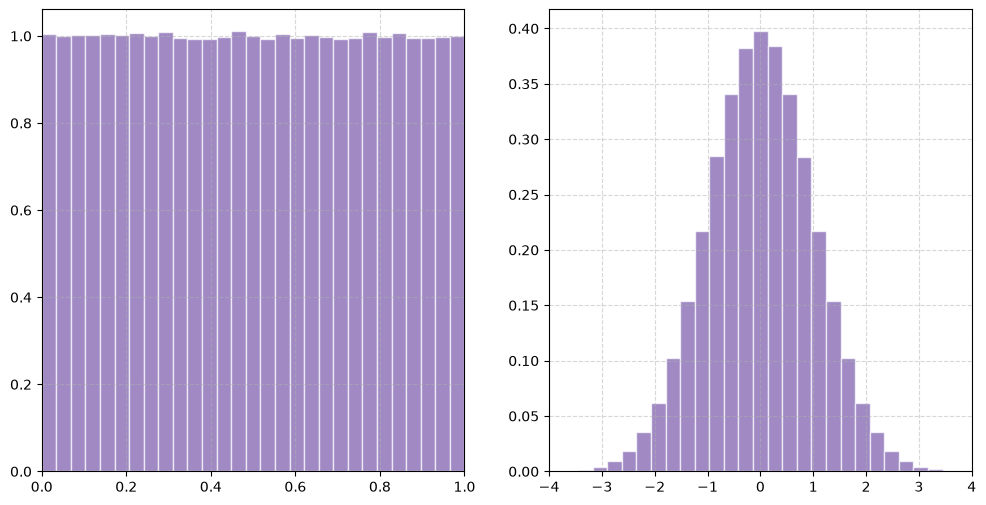

In [13]:
uniform = Uniform()
normal = Normal()
dists = [uniform, normal]

fig, axes = plt.subplots(1,2, figsize=(12,6))

for dist, ax in zip(dists, axes):
    dist.plot(ax)

##### Write a class that implements the exponentially decaying distribution via inverse-transform sampling.

In [14]:
class Exponential(Distribution):
    def __init__(self, size=1000000, lambd=1.0):
        self.lambd = lambd
        super().__init__(size=size)


    def set_xs(self):
        self.min = 0
        self.max = 5
        sample = np.random.rand(self.size)
        self.xs = -self.lambd * np.log(1-sample) # Equation 1.24 from notes
        
        


In [15]:
class Exponential(Distribution):
    def __init__(self, l=1, size=10000):
        self.l = l
        self.rng = np.random.default_rng()
        xmax = self.inverse_cdf(0.999)
        super().__init__(size=size, min=0, max=xmax)

    def set_xs(self):
        u = self.rng.random(self.size)
        self.xs = self.inverse_cdf(u)

    def PDF(self, x):
        return self.l * np.exp(-self.l*x)

    def CDF(self, x):
        return 1 - np.exp(-self.l*x)

    def inverse_cdf(self, u):
        return -np.log(1 - u) / self.l 

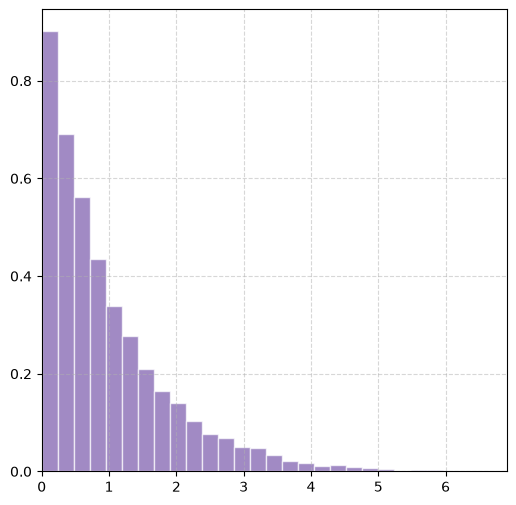

In [16]:
exp = Exponential()

fig, ax = plt.subplots(figsize=(6,6))
exp.plot(ax)

#### 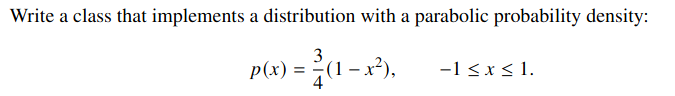

In [17]:
class Parabolic(Distribution):
    def set_xs(self):
        self.min = -1
        self.max = 1
        sample_y = np.random.uniform(0,.75,self.size)
        sample_x = np.random.uniform(-1,1,self.size)
        p_x = 3 * (1 - sample_x**2) / 4
        self.xs = sample_x[sample_y <= p_x]

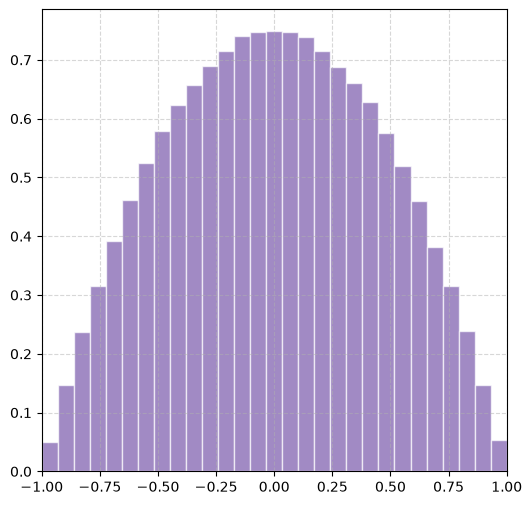

In [18]:
para = Parabolic()

fig, ax = plt.subplots(figsize=(6,6))
para.plot(ax)

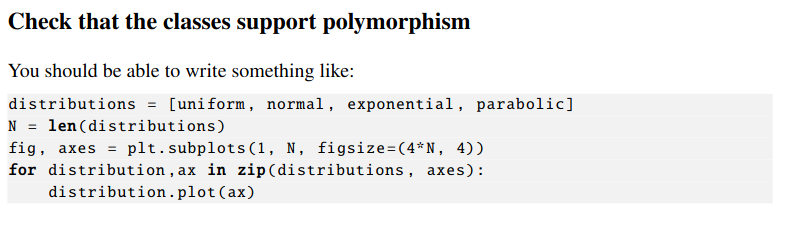

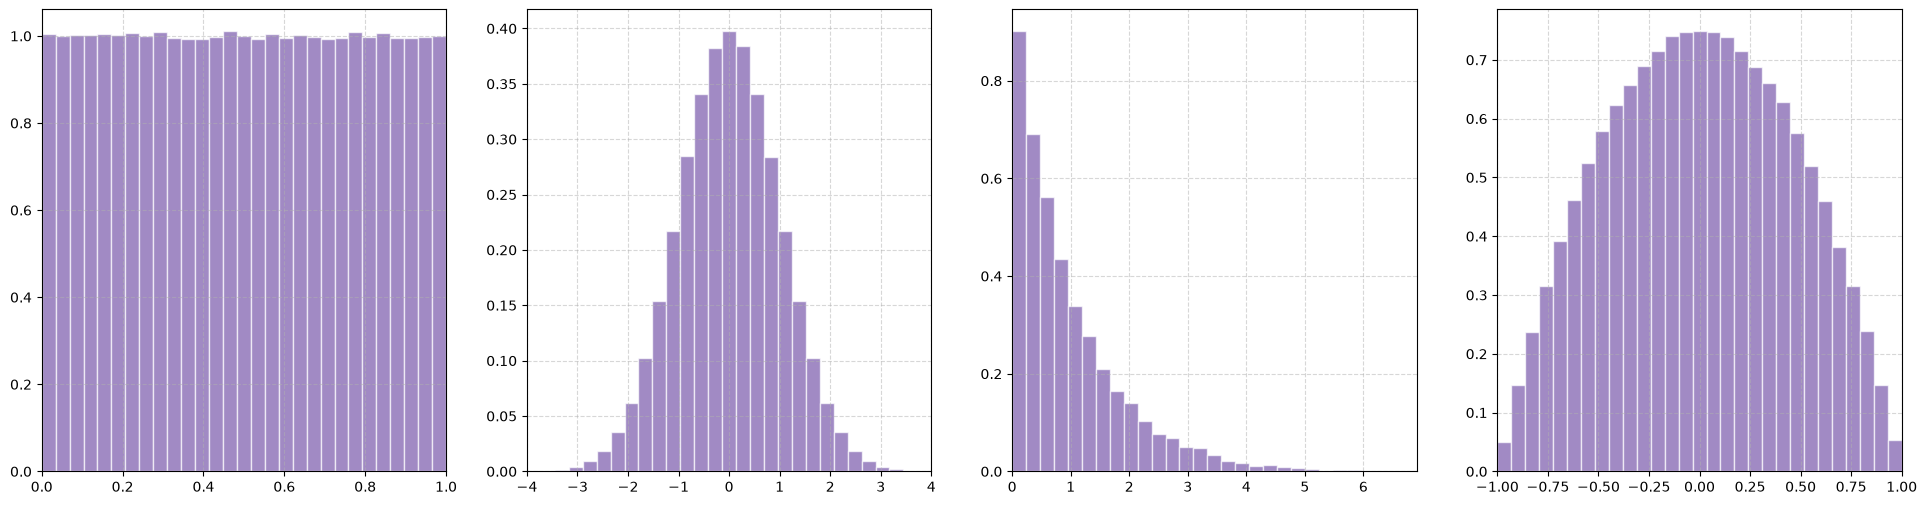

In [19]:
dists = [uniform, normal, exp, para]

fig, axes = plt.subplots(1,4, figsize=(24,6))

for dist, ax in zip(dists, axes):
    dist.plot(ax)